In [ ]:
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully!


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
base_path = "/content/drive/MyDrive/AML_Project"

print("Project folders:")
print(os.listdir(base_path))

Project folders:
['notebooks', 'dataset', 'outputs', 'dashboard', 'report']


In [ ]:
output_path = os.path.join(
    base_path,
    "outputs"
)

print("Available outputs:")

for file in os.listdir(output_path):
    print(file)

Available outputs:
prefixspan_top_patterns.png
prefixspan_results.csv
rich_prefixspan_results.csv
gsp_results.csv
fraud_pattern_coverage.csv
algorithm_comparison.csv
spatial_city_hotspots.csv
kmeans_spatial_clusters.csv
dbscan_spatial_clusters.csv
spatial_clustering_comparison.csv
rapidgeo_threshold_evaluation.csv
spatial_mining_summary.csv
integrated_fraud_type_results.csv
sequential_spatial_model_comparison.csv
integrated_risk_threshold_results.csv
final_integrated_results.csv
integrated_transaction_risk_results.csv


In [ ]:
dataset_path = os.path.join(
    base_path,
    "dataset"
)

print("Dataset files:")
print(os.listdir(dataset_path))

Dataset files:
['cities.csv', 'customers.csv', 'atms.csv', 'merchants.csv', 'transactions.csv', 'fraud_transactions_v1.csv', 'fraud_transactions_complete.csv']


In [ ]:
file_path = os.path.join(
    dataset_path,
    "fraud_transactions_complete.csv"
)

df = pd.read_csv(file_path)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (149994, 15)


/tmp/ipykernel_1366/3670769437.py:6: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


,transaction_id,sender,receiver,receiver_name,is_merchant,transaction_type,amount,timestamp,atm_id,city,state,latitude,longitude,fraud_type,pattern_id
0,TX00007570,CUST01729,MER00193,Bharat Petroleum,True,Fuel,3002.0,2026-01-01 07:00:03,ATM0172,Delhi,Delhi,28.574159,77.160227,Normal,NaN
1,TX00017239,CUST04035,MER00158,Bharat Petroleum,True,Fuel,620.0,2026-01-01 07:00:06,ATM0111,Patna,Bihar,25.642494,85.148727,Normal,NaN
2,TX00010111,CUST02337,CUST01403,CUST01403,False,Transfer,33077.0,2026-01-01 07:00:08,ATM0068,Bhopal,Madhya Pradesh,23.255729,77.462445,Normal,NaN
3,TX00009240,CUST02134,CUST02339,CUST02339,False,Card,6389.0,2026-01-01 07:00:10,ATM0171,Jaipur,Rajasthan,26.917736,75.807042,Normal,NaN
4,TX00009635,CUST02235,CUST04794,CUST04794,False,ATM,3950.0,2026-01-01 07:00:11,ATM0155,Chandigarh,Chandigarh,30.766373,76.738066,Normal,NaN


In [ ]:
print("Fraud distribution:")
display(
    df["fraud_type"]
    .value_counts()
    .to_frame("transactions")
)

Fraud distribution:


,transactions
fraud_type,
Normal,148544
Mule,300
Structuring,300
Smurfing,250
Layering,200
Circular,200
RapidGeographicMovement,200


In [ ]:
df["is_fraud"] = (
    df["fraud_type"] != "Normal"
).astype(int)

print(
    "Total fraudulent transactions:",
    df["is_fraud"].sum()
)

print(
    "Total normal transactions:",
    (df["is_fraud"] == 0).sum()
)

Total fraudulent transactions: 1450
Total normal transactions: 148544


In [ ]:
RAPID_DISTANCE_THRESHOLD = 1000
RAPID_TIME_THRESHOLD = 8

df = df.sort_values(
    ["sender", "timestamp"]
).reset_index(drop=True)

df["previous_latitude"] = (
    df.groupby("sender")["latitude"].shift(1)
)

df["previous_longitude"] = (
    df.groupby("sender")["longitude"].shift(1)
)

df["previous_timestamp"] = (
    df.groupby("sender")["timestamp"].shift(1)
)

df["time_gap_minutes"] = (
    (
        df["timestamp"]
        -
        df["previous_timestamp"]
    ).dt.total_seconds() / 60
)

In [ ]:
from math import radians, sin, cos, sqrt, atan2

def haversine_distance(
    lat1,
    lon1,
    lat2,
    lon2
):

    R = 6371.0088

    lat1 = radians(lat1)
    lon1 = radians(lon1)

    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        +
        cos(lat1)
        * cos(lat2)
        * sin(dlon / 2) ** 2
    )

    c = 2 * atan2(
        sqrt(a),
        sqrt(1 - a)
    )

    return R * c

In [ ]:
def calculate_distance(row):

    if pd.isna(row["previous_latitude"]):
        return 0.0

    return haversine_distance(
        row["previous_latitude"],
        row["previous_longitude"],
        row["latitude"],
        row["longitude"]
    )


df["distance_km"] = df.apply(
    calculate_distance,
    axis=1
)

df["rapid_geo_flag"] = (
    (df["time_gap_minutes"] > 0) &
    (df["time_gap_minutes"] <= RAPID_TIME_THRESHOLD) &
    (df["distance_km"] >= RAPID_DISTANCE_THRESHOLD)
).astype(int)

print("Spatial features created!")

display(
    df[
        [
            "sender",
            "timestamp",
            "city",
            "distance_km",
            "time_gap_minutes",
            "rapid_geo_flag",
            "fraud_type"
        ]
    ].head(20)
)

Spatial features created!


,sender,timestamp,city,distance_km,time_gap_minutes,rapid_geo_flag,fraud_type
0,CUST00001,2026-01-01 14:08:47,Ahmedabad,0.000000,NaN,0,Normal
1,CUST00001,2026-01-02 13:31:46,Kochi,1498.451932,1402.983333,0,Normal
2,CUST00001,2026-01-02 18:10:34,Bhopal,1481.998508,278.800000,0,Normal
3,CUST00001,2026-01-02 22:02:10,Visakhapatnam,861.471290,231.600000,0,Normal
4,CUST00001,2026-01-03 07:55:52,Hyderabad,492.443185,593.700000,0,Normal
5,CUST00001,2026-01-03 11:30:27,Indore,651.863764,214.583333,0,Normal
6,CUST00001,2026-01-04 08:02:30,Chandigarh,901.206247,1232.050000,0,Normal
7,CUST00001,2026-01-05 11:59:43,Hyderabad,1490.182402,1677.216667,0,Normal
8,CUST00001,2026-01-05 15:33:14,Coimbatore,731.155136,213.516667,0,Normal
9,CUST00001,2026-01-06 13:11:20,Surat,1220.441043,1298.100000,0,Normal


In [ ]:
rapid_actual = df[
    df["fraud_type"] == "RapidGeographicMovement"
]

print(
    "RapidGeo planted transactions:",
    len(rapid_actual)
)

print(
    "RapidGeo transactions detected:",
    rapid_actual["rapid_geo_flag"].sum()
)

rapid_patterns_detected = (
    df[
        (df["fraud_type"] == "RapidGeographicMovement") &
        (df["rapid_geo_flag"] == 1)
    ]["pattern_id"]
    .dropna()
    .nunique()
)

rapid_patterns_total = (
    df[
        df["fraud_type"] == "RapidGeographicMovement"
    ]["pattern_id"]
    .dropna()
    .nunique()
)

print(
    "RapidGeo patterns detected:",
    rapid_patterns_detected,
    "/",
    rapid_patterns_total
)

RapidGeo planted transactions: 200
RapidGeo transactions detected: 94
RapidGeo patterns detected: 48 / 50


In [ ]:
# Cell 12 — Sequential Context

df["previous_transaction_type"] = (
    df.groupby("sender")["transaction_type"]
    .shift(1)
)

df["previous_previous_type"] = (
    df.groupby("sender")["transaction_type"]
    .shift(2)
)

df["sequence_2"] = (
    df["previous_transaction_type"]
    .fillna("")
    + " → "
    + df["transaction_type"]
)

df["sequence_3"] = (
    df["previous_previous_type"]
    .fillna("")
    + " → "
    + df["previous_transaction_type"].fillna("")
    + " → "
    + df["transaction_type"]
)

display(
    df[
        [
            "sender",
            "timestamp",
            "transaction_type",
            "previous_transaction_type",
            "sequence_2",
            "sequence_3",
            "fraud_type"
        ]
    ].head(20)
)

,sender,timestamp,transaction_type,previous_transaction_type,sequence_2,sequence_3,fraud_type
0,CUST00001,2026-01-01 14:08:47,Card,NaN,→ Card,→ → Card,Normal
1,CUST00001,2026-01-02 13:31:46,Fuel,Card,Card → Fuel,→ Card → Fuel,Normal
2,CUST00001,2026-01-02 18:10:34,Fuel,Fuel,Fuel → Fuel,Card → Fuel → Fuel,Normal
3,CUST00001,2026-01-02 22:02:10,UPI,Fuel,Fuel → UPI,Fuel → Fuel → UPI,Normal
4,CUST00001,2026-01-03 07:55:52,Fuel,UPI,UPI → Fuel,Fuel → UPI → Fuel,Normal
5,CUST00001,2026-01-03 11:30:27,UPI,Fuel,Fuel → UPI,UPI → Fuel → UPI,Normal
6,CUST00001,2026-01-04 08:02:30,Shopping,UPI,UPI → Shopping,Fuel → UPI → Shopping,Normal
7,CUST00001,2026-01-05 11:59:43,Fuel,Shopping,Shopping → Fuel,UPI → Shopping → Fuel,Normal
8,CUST00001,2026-01-05 15:33:14,UPI,Fuel,Fuel → UPI,Shopping → Fuel → UPI,Normal
9,CUST00001,2026-01-06 13:11:20,Shopping,UPI,UPI → Shopping,Fuel → UPI → Shopping,Normal


In [ ]:
# Cell 13 — Suspicious Sequential Patterns

suspicious_patterns = {
    "Transfer → Transfer": 2,
    "Transfer → Transfer → Transfer": 3,
    "UPI → UPI": 1.5,
    "UPI → UPI → UPI": 2.5,
    "Cash Deposit → Transfer": 2,
    "Transfer → Cash Deposit": 2,
    "Shopping → Transfer": 1.5,
    "Transfer → Shopping": 1.5,
    "Card → Transfer": 1.5,
    "Transfer → Card": 1.5
}

print("Suspicious sequential patterns:")
for pattern, score in suspicious_patterns.items():
    print(f"{pattern:<35} Risk weight: {score}")

Suspicious sequential patterns:
Transfer → Transfer                 Risk weight: 2
Transfer → Transfer → Transfer      Risk weight: 3
UPI → UPI                           Risk weight: 1.5
UPI → UPI → UPI                     Risk weight: 2.5
Cash Deposit → Transfer             Risk weight: 2
Transfer → Cash Deposit             Risk weight: 2
Shopping → Transfer                 Risk weight: 1.5
Transfer → Shopping                 Risk weight: 1.5
Card → Transfer                     Risk weight: 1.5
Transfer → Card                     Risk weight: 1.5


In [ ]:
# Cell 14 — Sequential Risk Score

def calculate_sequential_risk(row):

    score = 0

    seq2 = row["sequence_2"]
    seq3 = row["sequence_3"]

    # Check 3-step patterns first
    if seq3 in suspicious_patterns:
        score += suspicious_patterns[seq3]

    # Check 2-step patterns
    if seq2 in suspicious_patterns:
        score += suspicious_patterns[seq2]

    return score


df["sequential_risk_raw"] = df.apply(
    calculate_sequential_risk,
    axis=1
)

print("Sequential risk calculated!")

display(
    df[
        [
            "sender",
            "timestamp",
            "transaction_type",
            "sequence_2",
            "sequence_3",
            "sequential_risk_raw",
            "fraud_type"
        ]
    ]
    .sort_values(
        "sequential_risk_raw",
        ascending=False
    )
    .head(20)
)

Sequential risk calculated!


,sender,timestamp,transaction_type,sequence_2,sequence_3,sequential_risk_raw,fraud_type
43043,CUST01408,2026-01-04 07:40:17,Transfer,Transfer → Transfer,Transfer → Transfer → Transfer,5.0,Normal
43042,CUST01408,2026-01-03 22:08:32,Transfer,Transfer → Transfer,Transfer → Transfer → Transfer,5.0,Normal
5053,CUST00163,2026-01-06 03:19:00,Transfer,Transfer → Transfer,Transfer → Transfer → Transfer,5.0,RapidGeographicMovement
5052,CUST00163,2026-01-06 03:11:00,Transfer,Transfer → Transfer,Transfer → Transfer → Transfer,5.0,RapidGeographicMovement
5051,CUST00163,2026-01-06 03:05:00,Transfer,Transfer → Transfer,Transfer → Transfer → Transfer,5.0,RapidGeographicMovement
5050,CUST00163,2026-01-06 02:57:00,Transfer,Transfer → Transfer,Transfer → Transfer → Transfer,5.0,RapidGeographicMovement
24598,CUST00788,2026-01-02 18:53:47,Transfer,Transfer → Transfer,Transfer → Transfer → Transfer,5.0,Normal
56732,CUST01874,2026-01-05 11:24:08,Transfer,Transfer → Transfer,Transfer → Transfer → Transfer,5.0,Normal
24603,CUST00788,2026-01-03 16:54:54,Transfer,Transfer → Transfer,Transfer → Transfer → Transfer,5.0,Normal
43013,CUST01406,2026-01-05 13:37:27,Transfer,Transfer → Transfer,Transfer → Transfer → Transfer,5.0,Normal


In [ ]:
# Cell 15 — Normalize Sequential Risk

max_seq_risk = df[
    "sequential_risk_raw"
].max()

if max_seq_risk > 0:

    df["sequential_risk"] = (
        df["sequential_risk_raw"]
        /
        max_seq_risk
        * 100
    )

else:

    df["sequential_risk"] = 0

print(
    "Sequential risk range:",
    df["sequential_risk"].min(),
    "to",
    df["sequential_risk"].max()
)

Sequential risk range: 0.0 to 100.0


In [ ]:
# Cell 16 — Spatial Risk Score

df["spatial_risk"] = 0.0

rapid_mask = (
    df["rapid_geo_flag"] == 1
)

df.loc[
    rapid_mask,
    "spatial_risk"
] = 100

print("Spatial risk calculated!")

display(
    df[
        [
            "sender",
            "city",
            "distance_km",
            "time_gap_minutes",
            "rapid_geo_flag",
            "spatial_risk",
            "fraud_type"
        ]
    ]
    .sort_values(
        "spatial_risk",
        ascending=False
    )
    .head(20)
)

Spatial risk calculated!


,sender,city,distance_km,time_gap_minutes,rapid_geo_flag,spatial_risk,fraud_type
107391,CUST03557,Coimbatore,1771.553795,7.300000,1,100.0,Normal
52479,CUST01727,Bengaluru,1530.775440,6.400000,1,100.0,Normal
90489,CUST02983,Hyderabad,1254.243661,1.450000,1,100.0,Normal
33814,CUST01099,Kochi,1147.133322,2.400000,1,100.0,Normal
90494,CUST02983,Hyderabad,1076.833995,3.916667,1,100.0,Normal
98735,CUST03265,Lucknow,1800.216958,1.816667,1,100.0,Normal
5496,CUST00176,Indore,1100.662072,2.433333,1,100.0,Normal
15724,CUST00498,Kolkata,1613.145277,0.133333,1,100.0,Normal
98725,CUST03265,Ahmedabad,1239.992473,3.616667,1,100.0,Normal
58596,CUST01932,Chennai,1482.621971,1.366667,1,100.0,Normal


In [ ]:
# Cell 17 — Integrated Fraud Risk Score

SEQUENTIAL_WEIGHT = 0.60
SPATIAL_WEIGHT = 0.40

df["integrated_risk_score"] = (
    SEQUENTIAL_WEIGHT
    * df["sequential_risk"]
    +
    SPATIAL_WEIGHT
    * df["spatial_risk"]
)

print("Integrated risk score calculated!")

display(
    df[
        [
            "transaction_id",
            "sender",
            "transaction_type",
            "sequential_risk",
            "spatial_risk",
            "integrated_risk_score",
            "fraud_type"
        ]
    ]
    .sort_values(
        "integrated_risk_score",
        ascending=False
    )
    .head(20)
)

Integrated risk score calculated!


,transaction_id,sender,transaction_type,sequential_risk,spatial_risk,integrated_risk_score,fraud_type
91126,TX00140247,CUST03003,Transfer,100.0,100.0,100.0,Normal
86851,TX00097358,CUST02848,Transfer,100.0,100.0,100.0,Normal
46577,TX00091517,CUST01526,Transfer,100.0,100.0,100.0,Normal
89662,TX00076471,CUST02953,Transfer,100.0,100.0,100.0,Normal
43181,FRAUD001253,CUST01413,Transfer,100.0,100.0,100.0,RapidGeographicMovement
43905,TX00112408,CUST01437,Transfer,100.0,100.0,100.0,Normal
98101,FRAUD001396,CUST03243,Transfer,100.0,100.0,100.0,RapidGeographicMovement
124707,TX00123956,CUST04134,Transfer,100.0,100.0,100.0,Normal
124689,TX00144979,CUST04133,Transfer,100.0,100.0,100.0,Normal
142181,FRAUD001304,CUST04734,Transfer,100.0,100.0,100.0,RapidGeographicMovement


In [ ]:
# Cell 18 — Risk Categories

def classify_risk(score):

    if score >= 70:
        return "High Risk"

    elif score >= 40:
        return "Medium Risk"

    else:
        return "Low Risk"


df["risk_category"] = (
    df["integrated_risk_score"]
    .apply(classify_risk)
)

print("Risk categories created!")

print(
    df["risk_category"]
    .value_counts()
)

display(
    df[
        [
            "transaction_id",
            "integrated_risk_score",
            "risk_category",
            "fraud_type"
        ]
    ]
    .head(20)
)

Risk categories created!
risk_category
Low Risk       140002
Medium Risk      9770
High Risk         222
Name: count, dtype: int64


,transaction_id,integrated_risk_score,risk_category,fraud_type
0,TX00000001,0.0,Low Risk,Normal
1,TX00021204,0.0,Low Risk,Normal
2,TX00021206,0.0,Low Risk,Normal
3,TX00021205,0.0,Low Risk,Normal
4,TX00042517,0.0,Low Risk,Normal
5,TX00042516,0.0,Low Risk,Normal
6,TX00063995,0.0,Low Risk,Normal
7,TX00084834,0.0,Low Risk,Normal
8,TX00084833,0.0,Low Risk,Normal
9,TX00106302,0.0,Low Risk,Normal


In [ ]:
# Cell 19 — Risk Category vs Fraud Type

risk_fraud_table = pd.crosstab(
    df["risk_category"],
    df["fraud_type"]
)

display(risk_fraud_table)

fraud_type,Circular,Layering,Mule,Normal,RapidGeographicMovement,Smurfing,Structuring
risk_category,,,,,,,
High Risk,0,0,0,151,71,0,0
Low Risk,181,187,273,139113,57,89,102
Medium Risk,19,13,27,9280,72,161,198


In [ ]:
# Cell 20 — Fraud Detection by Risk Category

risk_summary = (
    df.groupby("risk_category")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraudulent_transactions=("is_fraud", "sum")
    )
    .reset_index()
)

risk_summary["fraud_rate_%"] = (
    risk_summary["fraudulent_transactions"]
    /
    risk_summary["total_transactions"]
    * 100
)

risk_order = [
    "Low Risk",
    "Medium Risk",
    "High Risk"
]

risk_summary["risk_category"] = pd.Categorical(
    risk_summary["risk_category"],
    categories=risk_order,
    ordered=True
)

risk_summary = risk_summary.sort_values(
    "risk_category"
)

display(risk_summary)

,risk_category,total_transactions,fraudulent_transactions,fraud_rate_%
1,Low Risk,140002,889,0.634991
2,Medium Risk,9770,490,5.015353
0,High Risk,222,71,31.981982


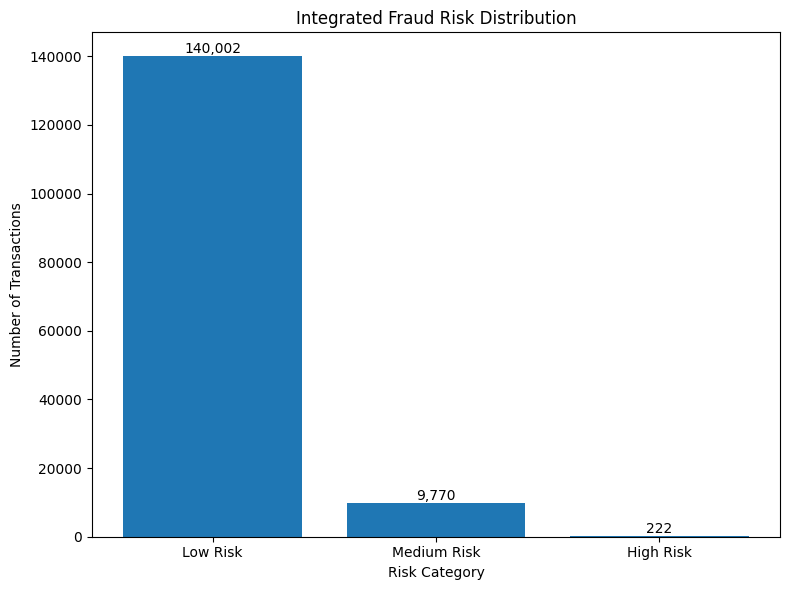

In [ ]:
# Cell 21 — Risk Category Distribution

plt.figure(figsize=(8, 6))

counts = (
    df["risk_category"]
    .value_counts()
    .reindex(risk_order)
)

bars = plt.bar(
    counts.index,
    counts.values
)

plt.xlabel("Risk Category")
plt.ylabel("Number of Transactions")
plt.title("Integrated Fraud Risk Distribution")

for bar, value in zip(bars, counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
# Cell 22 — Evaluate Multiple Risk Thresholds

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [
    10,
    20,
    30,
    40,
    50,
    60,
    70,
    80,
    90
]

threshold_results = []

for threshold in thresholds:

    predicted_fraud = (
        df["integrated_risk_score"] >= threshold
    ).astype(int)

    precision = precision_score(
        df["is_fraud"],
        predicted_fraud,
        zero_division=0
    )

    recall = recall_score(
        df["is_fraud"],
        predicted_fraud,
        zero_division=0
    )

    f1 = f1_score(
        df["is_fraud"],
        predicted_fraud,
        zero_division=0
    )

    threshold_results.append({
        "threshold": threshold,
        "alerts": predicted_fraud.sum(),
        "precision_%": precision * 100,
        "recall_%": recall * 100,
        "F1_%": f1 * 100
    })

threshold_results = pd.DataFrame(
    threshold_results
)

display(threshold_results)

,threshold,alerts,precision_%,recall_%,F1_%
0,10,41311,2.481179,70.689655,4.794088
1,20,21007,3.884419,56.275862,7.267222
2,30,9992,5.614492,38.689655,9.805978
3,40,9992,5.614492,38.689655,9.805978
4,50,5600,9.964286,38.482759,15.829787
5,60,5083,10.958096,38.413793,17.051890
6,70,222,31.981982,4.896552,8.492823
7,80,222,31.981982,4.896552,8.492823
8,90,169,42.011834,4.896552,8.770846


In [ ]:
# Cell 23 — Best Integrated Risk Threshold

best_result = threshold_results.loc[
    threshold_results["F1_%"].idxmax()
]

print("BEST INTEGRATED RISK THRESHOLD")
print("--------------------------------")
print(
    "Risk threshold:",
    best_result["threshold"]
)

print(
    "Alerts:",
    int(best_result["alerts"])
)

print(
    f"Precision: {best_result['precision_%']:.2f}%"
)

print(
    f"Recall: {best_result['recall_%']:.2f}%"
)

print(
    f"F1 Score: {best_result['F1_%']:.2f}%"
)

BEST INTEGRATED RISK THRESHOLD
--------------------------------
Risk threshold: 60.0
Alerts: 5083
Precision: 10.96%
Recall: 38.41%
F1 Score: 17.05%


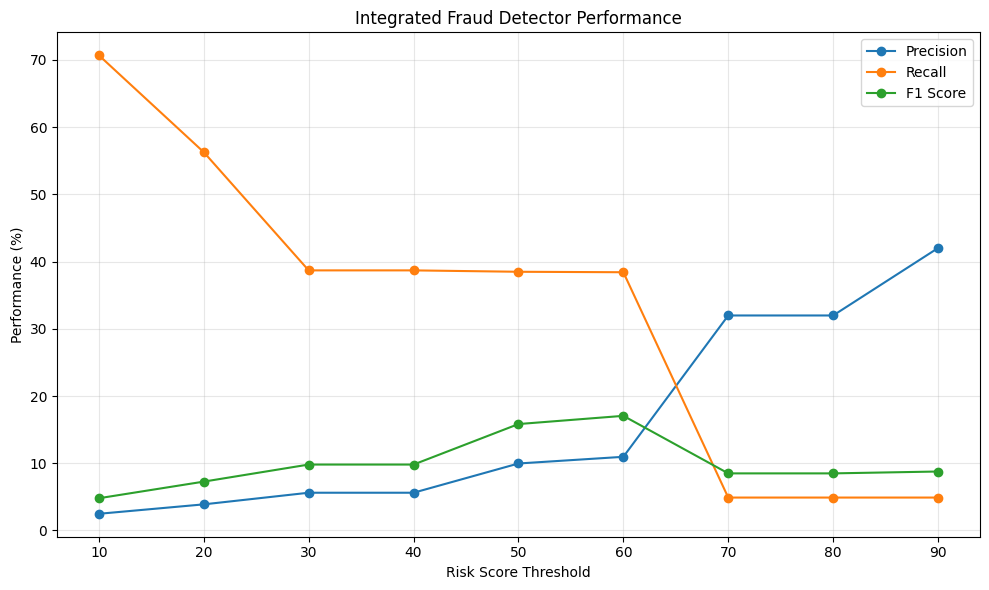

In [ ]:
# Cell 24 — Threshold Performance

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision_%"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall_%"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["F1_%"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Risk Score Threshold")
plt.ylabel("Performance (%)")

plt.title(
    "Integrated Fraud Detector Performance"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()

In [ ]:
# Cell 25 — Final Integrated Fraud Prediction

BEST_THRESHOLD = float(
    best_result["threshold"]
)

df["predicted_fraud"] = (
    df["integrated_risk_score"]
    >= BEST_THRESHOLD
).astype(int)

df["final_prediction"] = np.where(
    df["predicted_fraud"] == 1,
    "Fraud Alert",
    "Normal"
)

print(
    "Final integrated threshold:",
    BEST_THRESHOLD
)

print(
    "Total fraud alerts:",
    df["predicted_fraud"].sum()
)

display(
    df[
        [
            "transaction_id",
            "sender",
            "integrated_risk_score",
            "risk_category",
            "predicted_fraud",
            "fraud_type"
        ]
    ]
    .sort_values(
        "integrated_risk_score",
        ascending=False
    )
    .head(30)
)

Final integrated threshold: 60.0
Total fraud alerts: 5083


,transaction_id,sender,integrated_risk_score,risk_category,predicted_fraud,fraud_type
91126,TX00140247,CUST03003,100.0,High Risk,1,Normal
86851,TX00097358,CUST02848,100.0,High Risk,1,Normal
46577,TX00091517,CUST01526,100.0,High Risk,1,Normal
89662,TX00076471,CUST02953,100.0,High Risk,1,Normal
43181,FRAUD001253,CUST01413,100.0,High Risk,1,RapidGeographicMovement
43905,TX00112408,CUST01437,100.0,High Risk,1,Normal
98101,FRAUD001396,CUST03243,100.0,High Risk,1,RapidGeographicMovement
124707,TX00123956,CUST04134,100.0,High Risk,1,Normal
124689,TX00144979,CUST04133,100.0,High Risk,1,Normal
142181,FRAUD001304,CUST04734,100.0,High Risk,1,RapidGeographicMovement


Confusion Matrix:
[[144018   4526]
 [   893    557]]


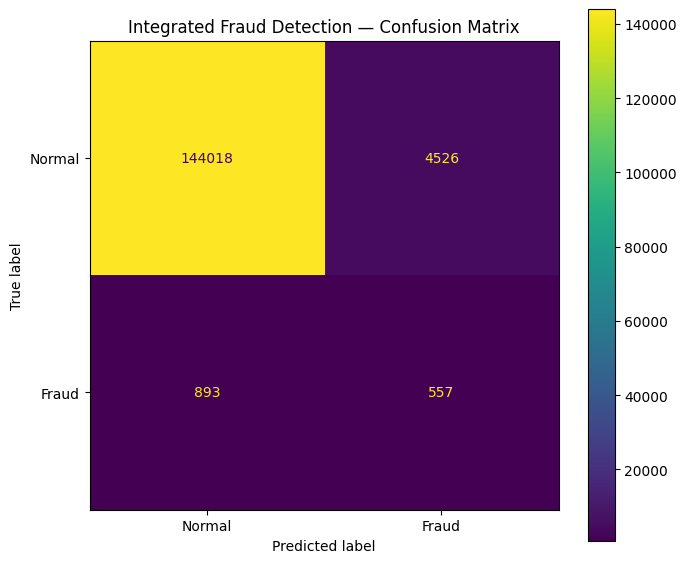

In [ ]:
# Cell 26 — Confusion Matrix

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

cm = confusion_matrix(
    df["is_fraud"],
    df["predicted_fraud"]
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title(
    "Integrated Fraud Detection — Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [ ]:
# Cell 27 — Final Model Metrics

precision = precision_score(
    df["is_fraud"],
    df["predicted_fraud"],
    zero_division=0
)

recall = recall_score(
    df["is_fraud"],
    df["predicted_fraud"],
    zero_division=0
)

f1 = f1_score(
    df["is_fraud"],
    df["predicted_fraud"],
    zero_division=0
)

print("FINAL INTEGRATED DETECTOR")
print("=" * 40)
print(f"Threshold : {BEST_THRESHOLD}")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

FINAL INTEGRATED DETECTOR
Threshold : 60.0
Precision : 10.96%
Recall    : 38.41%
F1 Score  : 17.05%


In [ ]:
# Cell 28 — Fraud-Type Detection Performance

fraud_types = [
    "Circular",
    "Layering",
    "Mule",
    "Smurfing",
    "Structuring",
    "RapidGeographicMovement"
]

fraud_type_results = []

for fraud_type in fraud_types:

    actual = (
        df["fraud_type"] == fraud_type
    ).astype(int)

    predicted = df["predicted_fraud"]

    tp = (
        (actual == 1) &
        (predicted == 1)
    ).sum()

    fn = (
        (actual == 1) &
        (predicted == 0)
    ).sum()

    fp = (
        (actual == 0) &
        (predicted == 1)
    ).sum()

    type_precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    type_recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    type_f1 = (
        2 * type_precision * type_recall /
        (type_precision + type_recall)
        if (type_precision + type_recall) > 0
        else 0
    )

    fraud_type_results.append({
        "fraud_type": fraud_type,
        "actual_transactions": int(actual.sum()),
        "detected_transactions": int(tp),
        "false_negatives": int(fn),
        "precision_%": type_precision * 100,
        "recall_%": type_recall * 100,
        "F1_%": type_f1 * 100
    })

fraud_type_results = pd.DataFrame(
    fraud_type_results
)

display(fraud_type_results)

,fraud_type,actual_transactions,detected_transactions,false_negatives,precision_%,recall_%,F1_%
0,Circular,200,19,181,0.373795,9.500000,0.719288
1,Layering,200,13,187,0.255754,6.500000,0.492145
2,Mule,300,26,274,0.511509,8.666667,0.966004
3,Smurfing,250,160,90,3.147747,64.000000,6.000375
4,Structuring,300,198,102,3.895337,66.000000,7.356493
5,RapidGeographicMovement,200,141,59,2.773952,70.500000,5.337876


In [ ]:
# Cell 28 — Fraud-Type Detection Performance

fraud_types = [
    "Circular",
    "Layering",
    "Mule",
    "Smurfing",
    "Structuring",
    "RapidGeographicMovement"
]

fraud_type_results = []

for fraud_type in fraud_types:

    actual = (
        df["fraud_type"] == fraud_type
    ).astype(int)

    predicted = df["predicted_fraud"]

    tp = (
        (actual == 1) &
        (predicted == 1)
    ).sum()

    fn = (
        (actual == 1) &
        (predicted == 0)
    ).sum()

    fp = (
        (actual == 0) &
        (predicted == 1)
    ).sum()

    type_precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    type_recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    type_f1 = (
        2 * type_precision * type_recall /
        (type_precision + type_recall)
        if (type_precision + type_recall) > 0
        else 0
    )

    fraud_type_results.append({
        "fraud_type": fraud_type,
        "actual_transactions": int(actual.sum()),
        "detected_transactions": int(tp),
        "false_negatives": int(fn),
        "precision_%": type_precision * 100,
        "recall_%": type_recall * 100,
        "F1_%": type_f1 * 100
    })

fraud_type_results = pd.DataFrame(
    fraud_type_results
)

display(fraud_type_results)

,fraud_type,actual_transactions,detected_transactions,false_negatives,precision_%,recall_%,F1_%
0,Circular,200,19,181,0.373795,9.500000,0.719288
1,Layering,200,13,187,0.255754,6.500000,0.492145
2,Mule,300,26,274,0.511509,8.666667,0.966004
3,Smurfing,250,160,90,3.147747,64.000000,6.000375
4,Structuring,300,198,102,3.895337,66.000000,7.356493
5,RapidGeographicMovement,200,141,59,2.773952,70.500000,5.337876


In [ ]:
# Cell 30 — Sequential vs Spatial vs Integrated

df["sequential_alert"] = (
    df["sequential_risk_raw"] > 0
).astype(int)

df["spatial_alert"] = (
    df["rapid_geo_flag"] == 1
).astype(int)

models = {
    "Sequential Only": df["sequential_alert"],
    "Spatial Only": df["spatial_alert"],
    "Integrated": df["predicted_fraud"]
}

model_comparison = []

for model_name, predictions in models.items():

    p = precision_score(
        df["is_fraud"],
        predictions,
        zero_division=0
    )

    r = recall_score(
        df["is_fraud"],
        predictions,
        zero_division=0
    )

    f = f1_score(
        df["is_fraud"],
        predictions,
        zero_division=0
    )

    model_comparison.append({
        "Model": model_name,
        "Alerts": int(predictions.sum()),
        "Precision_%": p * 100,
        "Recall_%": r * 100,
        "F1_%": f * 100
    })

model_comparison = pd.DataFrame(
    model_comparison
)

display(model_comparison)

,Model,Alerts,Precision_%,Recall_%,F1_%
0,Sequential Only,38871,2.629209,70.482759,5.069319
1,Spatial Only,3447,2.785030,6.620690,3.920768
2,Integrated,5083,10.958096,38.413793,17.051890


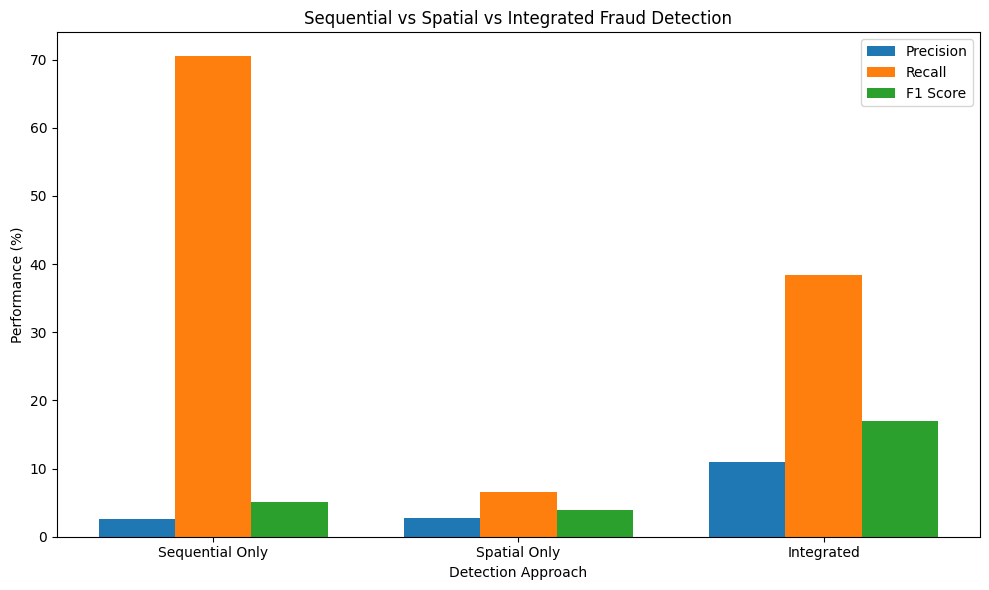

In [ ]:
# Cell 31 — Model Performance Comparison

x = np.arange(
    len(model_comparison["Model"])
)

width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(
    x - width,
    model_comparison["Precision_%"],
    width,
    label="Precision"
)

plt.bar(
    x,
    model_comparison["Recall_%"],
    width,
    label="Recall"
)

plt.bar(
    x + width,
    model_comparison["F1_%"],
    width,
    label="F1 Score"
)

plt.xticks(
    x,
    model_comparison["Model"]
)

plt.ylabel("Performance (%)")

plt.xlabel("Detection Approach")

plt.title(
    "Sequential vs Spatial vs Integrated Fraud Detection"
)

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
# Cell 32 — Final Results Summary

final_results = pd.DataFrame({
    "Metric": [
        "Dataset Transactions",
        "Total Fraud Transactions",
        "Integrated Risk Threshold",
        "Total Fraud Alerts",
        "Precision",
        "Recall",
        "F1 Score",
        "RapidGeo Pattern Coverage"
    ],
    "Value": [
        len(df),
        int(df["is_fraud"].sum()),
        BEST_THRESHOLD,
        int(df["predicted_fraud"].sum()),
        f"{precision * 100:.2f}%",
        f"{recall * 100:.2f}%",
        f"{f1 * 100:.2f}%",
        "48 / 50 (96.00%)"
    ]
})

display(final_results)

,Metric,Value
0,Dataset Transactions,149994
1,Total Fraud Transactions,1450
2,Integrated Risk Threshold,60.0
3,Total Fraud Alerts,5083
4,Precision,10.96%
5,Recall,38.41%
6,F1 Score,17.05%
7,RapidGeo Pattern Coverage,48 / 50 (96.00%)


In [ ]:
# Cell 33 — Save NB8 Results

nb8_output = os.path.join(
    base_path,
    "outputs"
)

os.makedirs(
    nb8_output,
    exist_ok=True
)

fraud_type_results.to_csv(
    os.path.join(
        nb8_output,
        "integrated_fraud_type_results.csv"
    ),
    index=False
)

model_comparison.to_csv(
    os.path.join(
        nb8_output,
        "sequential_spatial_model_comparison.csv"
    ),
    index=False
)

threshold_results.to_csv(
    os.path.join(
        nb8_output,
        "integrated_risk_threshold_results.csv"
    ),
    index=False
)

final_results.to_csv(
    os.path.join(
        nb8_output,
        "final_integrated_results.csv"
    ),
    index=False
)

df.to_csv(
    os.path.join(
        nb8_output,
        "integrated_transaction_risk_results.csv"
    ),
    index=False
)

print("All NB8 integrated results saved successfully!")

All NB8 integrated results saved successfully!


In [ ]:
# Cell 34 — Improved Spatial Risk Score

df["spatial_risk_v2"] = 0.0

# Distance component
distance_component = np.clip(
    df["distance_km"] / 2000,
    0,
    1
) * 50

# Time component
time_component = (
    np.clip(
        (10 - df["time_gap_minutes"]) / 10,
        0,
        1
    ) * 30
)

# RapidGeo bonus
rapid_bonus = (
    df["rapid_geo_flag"] * 20
)

df["spatial_risk_v2"] = (
    distance_component
    +
    time_component
    +
    rapid_bonus
)

df["spatial_risk_v2"] = np.clip(
    df["spatial_risk_v2"],
    0,
    100
)

print("Improved spatial risk calculated!")

display(
    df[
        [
            "sender",
            "distance_km",
            "time_gap_minutes",
            "rapid_geo_flag",
            "spatial_risk_v2",
            "fraud_type"
        ]
    ]
    .sort_values(
        "spatial_risk_v2",
        ascending=False
    )
    .head(20)
)

Improved spatial risk calculated!


,sender,distance_km,time_gap_minutes,rapid_geo_flag,spatial_risk_v2,fraud_type
49552,CUST01621,2080.379221,0.150000,1,99.550000,Normal
54861,CUST01806,1993.511481,0.100000,1,99.537787,Normal
58796,CUST01939,2196.258146,0.216667,1,99.350000,Normal
76937,CUST02527,2085.302584,0.266667,1,99.200000,Normal
104127,CUST03445,2079.479294,0.283333,1,99.150000,Normal
148806,CUST04964,1976.563633,0.116667,1,99.064091,Normal
19353,CUST00610,1987.131184,0.250000,1,98.928280,Normal
57110,CUST01886,2079.143638,0.366667,1,98.900000,Normal
122448,CUST04059,1983.320831,0.250000,1,98.833021,Normal
77150,CUST02533,2194.746314,0.450000,1,98.650000,Normal


In [ ]:
# Cell 35 — Build Sequential Pattern Support Lookup

# We already have frequent_patterns from the sequential mining stage.
# If the variable exists, use it directly.

print("Checking sequential mining results...")

try:
    print("Number of frequent pattern levels:", len(frequent_patterns))
except NameError:
    print("frequent_patterns variable not found.")
    print("We'll use the previously generated pattern results if available.")

Checking sequential mining results...
frequent_patterns variable not found.
We'll use the previously generated pattern results if available.


In [ ]:
# Cell 35B — Load previously saved sequential patterns

print("Available output files:")

for file in os.listdir(
    "/content/drive/MyDrive/AML_Project/outputs"
):
    print(file)

Available output files:
prefixspan_top_patterns.png
prefixspan_results.csv
rich_prefixspan_results.csv
gsp_results.csv
fraud_pattern_coverage.csv
algorithm_comparison.csv
spatial_city_hotspots.csv
kmeans_spatial_clusters.csv
dbscan_spatial_clusters.csv
spatial_clustering_comparison.csv
rapidgeo_threshold_evaluation.csv
spatial_mining_summary.csv
integrated_fraud_type_results.csv
sequential_spatial_model_comparison.csv
integrated_risk_threshold_results.csv
final_integrated_results.csv
integrated_transaction_risk_results.csv


In [ ]:
# Cell 36 — Load Sequential Mining Results

output_path = "/content/drive/MyDrive/AML_Project/outputs"

rich_patterns_path = os.path.join(
    output_path,
    "rich_prefixspan_results.csv"
)

rich_patterns = pd.read_csv(
    rich_patterns_path
)

print("Rich sequential patterns loaded!")
print("Shape:", rich_patterns.shape)

display(rich_patterns.head(20))

Rich sequential patterns loaded!
Shape: (70, 3)


,support,pattern,length
0,9393,Transfer_MEDIUM,1
1,9260,UPI_LOW,1
2,6052,Shopping_LOW,1
3,5079,Bills_LOW,1
4,4680,ATM_LOW,1
5,3411,Shopping_MEDIUM,1
6,2740,Transfer_LOW,1
7,2672,Card_MEDIUM,1
8,2600,Transfer_MEDIUM → Transfer_MEDIUM,2
9,2564,Card_LOW,1


In [ ]:
# Cell 37 — Sequential Pattern Risk Weights

print("Columns in rich_patterns:")
print(rich_patterns.columns.tolist())

# Clean column names
rich_patterns.columns = (
    rich_patterns.columns
    .astype(str)
    .str.strip()
)

# Use the actual column names from rich_prefixspan_results.csv
rich_patterns["support"] = pd.to_numeric(
    rich_patterns["support"],
    errors="coerce"
)

rich_patterns["pattern_length"] = pd.to_numeric(
    rich_patterns["length"],
    errors="coerce"
)

# Remove invalid rows
rich_patterns = rich_patterns.dropna(
    subset=[
        "support",
        "pattern_length",
        "pattern"
    ]
).copy()

# Normalize support
max_support = rich_patterns["support"].max()

rich_patterns["support_strength"] = (
    rich_patterns["support"]
    / max_support
)

# Give longer patterns more importance
rich_patterns["length_weight"] = (
    rich_patterns["pattern_length"] ** 1.5
)

# Combined sequential pattern weight
rich_patterns["pattern_weight"] = (
    rich_patterns["support_strength"]
    * rich_patterns["length_weight"]
)

print("Sequential pattern weights created!")

print(
    "Number of usable patterns:",
    len(rich_patterns)
)

display(
    rich_patterns
    .sort_values(
        "pattern_weight",
        ascending=False
    )
    .head(20)
)

Columns in rich_patterns:
['support', 'pattern', 'length']
Sequential pattern weights created!
Number of usable patterns: 70


,support,pattern,length,pattern_length,support_strength,length_weight,pattern_weight
0,9393,Transfer_MEDIUM,1,1,1.000000,1.000000,1.000000
1,9260,UPI_LOW,1,1,0.985841,1.000000,0.985841
8,2600,Transfer_MEDIUM → Transfer_MEDIUM,2,2,0.276802,2.828427,0.782914
10,2402,UPI_LOW → UPI_LOW,2,2,0.255722,2.828427,0.723292
2,6052,Shopping_LOW,1,1,0.644310,1.000000,0.644310
3,5079,Bills_LOW,1,1,0.540722,1.000000,0.540722
4,4680,ATM_LOW,1,1,0.498243,1.000000,0.498243
14,1522,Bills_LOW → Bills_LOW,2,2,0.162036,2.828427,0.458306
16,1411,ATM_LOW → Bills_LOW,2,2,0.150218,2.828427,0.424881
17,1357,Bills_LOW → ATM_LOW,2,2,0.144469,2.828427,0.408621


In [ ]:
# Cell 38 — Pattern Lookup Dictionary

pattern_weights = dict(
    zip(
        rich_patterns["pattern"],
        rich_patterns["pattern_weight"]
    )
)

print(
    "Number of mined patterns available:",
    len(pattern_weights)
)

print("\nSample pattern weights:")

for pattern, weight in list(
    pattern_weights.items()
)[:20]:

    print(
        f"{pattern:<45} {weight:.4f}"
    )

Number of mined patterns available: 70

Sample pattern weights:
Transfer_MEDIUM                               1.0000
UPI_LOW                                       0.9858
Shopping_LOW                                  0.6443
Bills_LOW                                     0.5407
ATM_LOW                                       0.4982
Shopping_MEDIUM                               0.3631
Transfer_LOW                                  0.2917
Card_MEDIUM                                   0.2845
Transfer_MEDIUM → Transfer_MEDIUM             0.7829
Card_LOW                                      0.2730
UPI_LOW → UPI_LOW                             0.7233
Healthcare_MEDIUM                             0.1925
Food_LOW                                      0.1863
Fuel_LOW                                      0.1703
Bills_LOW → Bills_LOW                         0.4583
Cash Deposit_HIGH                             0.1526
ATM_LOW → Bills_LOW                           0.4249
Bills_LOW → ATM_LOW                

In [ ]:
# Cell 39 — Create Rich Transaction Representation

def amount_bucket(amount):
    if pd.isna(amount):
        return "UNKNOWN"
    elif amount < 10000:
        return "LOW"
    elif amount < 50000:
        return "MEDIUM"
    elif amount < 100000:
        return "HIGH"
    else:
        return "VERY_HIGH"


df["amount_level"] = df["amount"].apply(amount_bucket)

df["rich_transaction_type"] = (
    df["transaction_type"]
    + "_"
    + df["amount_level"]
)

print("Rich transaction representation created!")

display(
    df[
        [
            "transaction_type",
            "amount",
            "amount_level",
            "rich_transaction_type",
            "fraud_type"
        ]
    ].head(20)
)

Rich transaction representation created!


,transaction_type,amount,amount_level,rich_transaction_type,fraud_type
0,Card,8524.0,LOW,Card_LOW,Normal
1,Fuel,3595.0,LOW,Fuel_LOW,Normal
2,Fuel,1275.0,LOW,Fuel_LOW,Normal
3,UPI,3866.0,LOW,UPI_LOW,Normal
4,Fuel,921.0,LOW,Fuel_LOW,Normal
5,UPI,2073.0,LOW,UPI_LOW,Normal
6,Shopping,2136.0,LOW,Shopping_LOW,Normal
7,Fuel,1583.0,LOW,Fuel_LOW,Normal
8,UPI,775.0,LOW,UPI_LOW,Normal
9,Shopping,9195.0,LOW,Shopping_LOW,Normal


In [ ]:
# Cell 40 — Rich Sequential Context

df = df.sort_values(
    ["sender", "timestamp"]
).reset_index(drop=True)

df["previous_rich_type"] = (
    df.groupby("sender")["rich_transaction_type"]
    .shift(1)
)

df["previous_previous_rich_type"] = (
    df.groupby("sender")["rich_transaction_type"]
    .shift(2)
)

df["rich_sequence_2"] = (
    df["previous_rich_type"]
    .fillna("")
    + " → "
    + df["rich_transaction_type"]
)

df["rich_sequence_3"] = (
    df["previous_previous_rich_type"]
    .fillna("")
    + " → "
    + df["previous_rich_type"].fillna("")
    + " → "
    + df["rich_transaction_type"]
)

display(
    df[
        [
            "sender",
            "timestamp",
            "rich_transaction_type",
            "rich_sequence_2",
            "rich_sequence_3",
            "fraud_type"
        ]
    ].head(20)
)

,sender,timestamp,rich_transaction_type,rich_sequence_2,rich_sequence_3,fraud_type
0,CUST00001,2026-01-01 14:08:47,Card_LOW,→ Card_LOW,→ → Card_LOW,Normal
1,CUST00001,2026-01-02 13:31:46,Fuel_LOW,Card_LOW → Fuel_LOW,→ Card_LOW → Fuel_LOW,Normal
2,CUST00001,2026-01-02 18:10:34,Fuel_LOW,Fuel_LOW → Fuel_LOW,Card_LOW → Fuel_LOW → Fuel_LOW,Normal
3,CUST00001,2026-01-02 22:02:10,UPI_LOW,Fuel_LOW → UPI_LOW,Fuel_LOW → Fuel_LOW → UPI_LOW,Normal
4,CUST00001,2026-01-03 07:55:52,Fuel_LOW,UPI_LOW → Fuel_LOW,Fuel_LOW → UPI_LOW → Fuel_LOW,Normal
5,CUST00001,2026-01-03 11:30:27,UPI_LOW,Fuel_LOW → UPI_LOW,UPI_LOW → Fuel_LOW → UPI_LOW,Normal
6,CUST00001,2026-01-04 08:02:30,Shopping_LOW,UPI_LOW → Shopping_LOW,Fuel_LOW → UPI_LOW → Shopping_LOW,Normal
7,CUST00001,2026-01-05 11:59:43,Fuel_LOW,Shopping_LOW → Fuel_LOW,UPI_LOW → Shopping_LOW → Fuel_LOW,Normal
8,CUST00001,2026-01-05 15:33:14,UPI_LOW,Fuel_LOW → UPI_LOW,Shopping_LOW → Fuel_LOW → UPI_LOW,Normal
9,CUST00001,2026-01-06 13:11:20,Shopping_LOW,UPI_LOW → Shopping_LOW,Fuel_LOW → UPI_LOW → Shopping_LOW,Normal


In [ ]:
# Cell 41 — Sequential Risk v2

def get_sequential_risk(row):

    matched_scores = []

    current = row["rich_transaction_type"]
    seq2 = row["rich_sequence_2"]
    seq3 = row["rich_sequence_3"]

    # Longest pattern gets priority
    if seq3 in pattern_weights:
        matched_scores.append(
            pattern_weights[seq3]
        )

    if seq2 in pattern_weights:
        matched_scores.append(
            pattern_weights[seq2]
        )

    if current in pattern_weights:
        matched_scores.append(
            pattern_weights[current]
        )

    if not matched_scores:
        return 0.0

    return max(matched_scores)


df["sequential_risk_v2_raw"] = df.apply(
    get_sequential_risk,
    axis=1
)

print("Sequential Risk v2 calculated!")

print(
    "Transactions with sequential pattern match:",
    (df["sequential_risk_v2_raw"] > 0).sum()
)

display(
    df[
        [
            "transaction_id",
            "rich_transaction_type",
            "rich_sequence_2",
            "rich_sequence_3",
            "sequential_risk_v2_raw",
            "fraud_type"
        ]
    ]
    .sort_values(
        "sequential_risk_v2_raw",
        ascending=False
    )
    .head(30)
)

Sequential Risk v2 calculated!
Transactions with sequential pattern match: 148492


,transaction_id,rich_transaction_type,rich_sequence_2,rich_sequence_3,sequential_risk_v2_raw,fraud_type
14,TX00127475,Transfer_MEDIUM,Card_MEDIUM → Transfer_MEDIUM,Fuel_LOW → Card_MEDIUM → Transfer_MEDIUM,1.0,Normal
149990,TX00148539,Transfer_MEDIUM,Shopping_LOW → Transfer_MEDIUM,Shopping_LOW → Shopping_LOW → Transfer_MEDIUM,1.0,Normal
149987,TX00148538,Transfer_MEDIUM,Card_LOW → Transfer_MEDIUM,Transfer_MEDIUM → Card_LOW → Transfer_MEDIUM,1.0,Normal
149968,TX00084825,Transfer_MEDIUM,Transfer_LOW → Transfer_MEDIUM,Transfer_MEDIUM → Transfer_LOW → Transfer_MEDIUM,1.0,Normal
149966,TX00084827,Transfer_MEDIUM,Transfer_MEDIUM → Transfer_MEDIUM,Shopping_LOW → Transfer_MEDIUM → Transfer_MEDIUM,1.0,Normal
149965,TX00084819,Transfer_MEDIUM,Shopping_LOW → Transfer_MEDIUM,Transfer_MEDIUM → Shopping_LOW → Transfer_MEDIUM,1.0,Normal
49448,TX00028126,Transfer_MEDIUM,Transfer_MEDIUM → Transfer_MEDIUM,Transfer_MEDIUM → Transfer_MEDIUM → Transfer_M...,1.0,Normal
49452,TX00049527,Transfer_MEDIUM,Shopping_MEDIUM → Transfer_MEDIUM,Shopping_LOW → Shopping_MEDIUM → Transfer_MEDIUM,1.0,Normal
49457,TX00070751,Transfer_MEDIUM,UPI_LOW → Transfer_MEDIUM,UPI_LOW → UPI_LOW → Transfer_MEDIUM,1.0,Normal
49460,TX00070753,Transfer_MEDIUM,UPI_LOW → Transfer_MEDIUM,Shopping_MEDIUM → UPI_LOW → Transfer_MEDIUM,1.0,Normal


In [ ]:
# Cell 42 — Normalize Sequential Risk v2

max_seq_v2 = df[
    "sequential_risk_v2_raw"
].max()

if max_seq_v2 > 0:
    df["sequential_risk_v2"] = (
        df["sequential_risk_v2_raw"]
        / max_seq_v2
        * 100
    )
else:
    df["sequential_risk_v2"] = 0.0

print(
    "Sequential Risk v2 range:",
    df["sequential_risk_v2"].min(),
    "to",
    df["sequential_risk_v2"].max()
)

Sequential Risk v2 range: 0.0 to 100.0


In [ ]:
# Cell 43 — Verify Risk Components

print("Sequential Risk v2:")
print(
    df["sequential_risk_v2"].describe()
)

print("\nSpatial Risk v2:")

if "spatial_risk_v2" in df.columns:
    print(
        df["spatial_risk_v2"].describe()
    )
else:
    print("spatial_risk_v2 NOT FOUND")

Sequential Risk v2:
count    149994.000000
mean         55.987820
std          34.450755
min           0.000000
25%          27.296923
50%          54.072181
75%          98.584052
max         100.000000
Name: sequential_risk_v2, dtype: float64

Spatial Risk v2:
count    144994.000000
mean         25.164736
std          15.082657
min           0.000000
25%          13.619349
50%          23.743686
75%          33.963664
max          99.550000
Name: spatial_risk_v2, dtype: float64


In [ ]:
# Cell 44 — Integrated Risk v2

SEQUENTIAL_WEIGHT = 0.60
SPATIAL_WEIGHT = 0.40

df["integrated_risk_v2"] = (
    SEQUENTIAL_WEIGHT
    * df["sequential_risk_v2"]
    +
    SPATIAL_WEIGHT
    * df["spatial_risk_v2"]
)

print("Integrated Risk v2 calculated!")

print(
    df["integrated_risk_v2"].describe()
)

display(
    df[
        [
            "transaction_id",
            "sequential_risk_v2",
            "spatial_risk_v2",
            "integrated_risk_v2",
            "fraud_type"
        ]
    ]
    .sort_values(
        "integrated_risk_v2",
        ascending=False
    )
    .head(30)
)

Integrated Risk v2 calculated!
count    144994.000000
mean         43.653812
std          21.542076
min           0.000000
25%          24.724528
50%          41.409147
75%          65.127525
max          99.533208
Name: integrated_risk_v2, dtype: float64


,transaction_id,sequential_risk_v2,spatial_risk_v2,integrated_risk_v2,fraud_type
122448,TX00144666,100.000000,98.833021,99.533208,Normal
49717,TX00028182,100.000000,98.250000,99.300000,Normal
95298,TX00077256,100.000000,98.100000,99.240000,Normal
90616,TX00055385,100.000000,97.988502,99.195401,Normal
71240,TX00073923,100.000000,97.637314,99.054926,Normal
60171,TX00093585,100.000000,97.525838,99.010335,Normal
56829,TX00093054,100.000000,97.114179,98.845672,Normal
104127,TX00121029,98.584052,99.150000,98.810431,Normal
7410,TX00085867,100.000000,96.679439,98.671775,Normal
35498,TX00089923,98.584052,98.600000,98.590431,Normal


In [ ]:
# Cell 44 — Handle Missing Spatial Risk Values

print("Before filling:")
print("Spatial risk missing:",
      df["spatial_risk_v2"].isna().sum())

# Missing spatial information means no spatial evidence.
# Treat it as zero spatial risk rather than dropping transactions.
df["spatial_risk_v2"] = (
    df["spatial_risk_v2"]
    .fillna(0)
)

print("\nAfter filling:")
print("Spatial risk missing:",
      df["spatial_risk_v2"].isna().sum())

print(
    "\nSpatial Risk v2 range:",
    df["spatial_risk_v2"].min(),
    "to",
    df["spatial_risk_v2"].max()
)

print(
    "Total transactions:",
    len(df)
)

Before filling:
Spatial risk missing: 5000

After filling:
Spatial risk missing: 0

Spatial Risk v2 range: 0.0 to 99.55
Total transactions: 149994


In [ ]:
# Cell 45 — Integrated Risk v2

SEQUENTIAL_WEIGHT = 0.60
SPATIAL_WEIGHT = 0.40

df["integrated_risk_v2"] = (
    SEQUENTIAL_WEIGHT * df["sequential_risk_v2"]
    +
    SPATIAL_WEIGHT * df["spatial_risk_v2"]
)

print("Integrated Risk v2 calculated!")

print(
    df["integrated_risk_v2"].describe()
)

display(
    df[
        [
            "transaction_id",
            "sequential_risk_v2",
            "spatial_risk_v2",
            "integrated_risk_v2",
            "fraud_type"
        ]
    ]
    .sort_values(
        "integrated_risk_v2",
        ascending=False
    )
    .head(30)
)

Integrated Risk v2 calculated!
count    149994.000000
mean         43.323043
std          21.585433
min           0.000000
25%          24.339493
50%          41.103219
75%          64.924855
max          99.533208
Name: integrated_risk_v2, dtype: float64


,transaction_id,sequential_risk_v2,spatial_risk_v2,integrated_risk_v2,fraud_type
122448,TX00144666,100.000000,98.833021,99.533208,Normal
49717,TX00028182,100.000000,98.250000,99.300000,Normal
95298,TX00077256,100.000000,98.100000,99.240000,Normal
90616,TX00055385,100.000000,97.988502,99.195401,Normal
71240,TX00073923,100.000000,97.637314,99.054926,Normal
60171,TX00093585,100.000000,97.525838,99.010335,Normal
56829,TX00093054,100.000000,97.114179,98.845672,Normal
104127,TX00121029,98.584052,99.150000,98.810431,Normal
7410,TX00085867,100.000000,96.679439,98.671775,Normal
35498,TX00089923,98.584052,98.600000,98.590431,Normal


In [ ]:
# Cell 46 — Integrated Risk v2 Threshold Evaluation

from sklearn.metrics import precision_score, recall_score, f1_score

# Ground-truth fraud indicator
df["actual_fraud"] = (
    df["fraud_type"] != "Normal"
).astype(int)

threshold_results = []

thresholds = range(20, 96, 5)

for threshold in thresholds:

    predicted = (
        df["integrated_risk_v2"] >= threshold
    ).astype(int)

    precision = precision_score(
        df["actual_fraud"],
        predicted,
        zero_division=0
    )

    recall = recall_score(
        df["actual_fraud"],
        predicted,
        zero_division=0
    )

    f1 = f1_score(
        df["actual_fraud"],
        predicted,
        zero_division=0
    )

    threshold_results.append({
        "threshold": threshold,
        "alerts": int(predicted.sum()),
        "precision_%": precision * 100,
        "recall_%": recall * 100,
        "f1_%": f1 * 100
    })

threshold_results_df = pd.DataFrame(
    threshold_results
)

threshold_results_df = (
    threshold_results_df
    .sort_values(
        "f1_%",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Integrated Risk v2 threshold evaluation completed!")

display(
    threshold_results_df
)

Integrated Risk v2 threshold evaluation completed!


,threshold,alerts,precision_%,recall_%,f1_%
0,80,1630,2.453988,2.758621,2.597403
1,60,47913,1.045645,34.551724,2.029860
2,55,51864,0.965988,34.551724,1.879431
3,50,56697,0.883645,34.551724,1.723219
4,85,915,2.185792,1.379310,1.691332
5,45,66017,0.758895,34.551724,1.485171
6,65,37125,0.727273,18.620690,1.399870
7,75,8468,0.791214,4.620690,1.351079
8,40,77491,0.646527,34.551724,1.269302
9,35,88991,0.566349,34.758621,1.114539


In [ ]:
# Cell 47 — Best Integrated Risk v2 Threshold

best_v2 = threshold_results_df.iloc[0]

print("=" * 60)
print("BEST INTEGRATED RISK V2 THRESHOLD")
print("=" * 60)

print(
    f"Threshold : {best_v2['threshold']}"
)

print(
    f"Alerts    : {int(best_v2['alerts'])}"
)

print(
    f"Precision : {best_v2['precision_%']:.2f}%"
)

print(
    f"Recall    : {best_v2['recall_%']:.2f}%"
)

print(
    f"F1 Score  : {best_v2['f1_%']:.2f}%"
)

print("=" * 60)

print(
    "\nPrevious Integrated baseline F1: 17.05%"
)

print(
    f"Integrated v2 F1 improvement: "
    f"{best_v2['f1_%'] - 17.05:.2f} percentage points"
)

BEST INTEGRATED RISK V2 THRESHOLD
Threshold : 80.0
Alerts    : 1630
Precision : 2.45%
Recall    : 2.76%
F1 Score  : 2.60%

Previous Integrated baseline F1: 17.05%
Integrated v2 F1 improvement: -14.45 percentage points


In [ ]:
# Cell 48 — Final Integrated Risk v2 Alerts

BEST_THRESHOLD_V2 = best_v2["threshold"]

df["integrated_alert_v2"] = (
    df["integrated_risk_v2"]
    >= BEST_THRESHOLD_V2
)

df["predicted_fraud_v2"] = (
    df["integrated_alert_v2"]
    .astype(int)
)

print(
    "Final Integrated Risk v2 alerts:",
    df["integrated_alert_v2"].sum()
)

print("\nFraud distribution among alerts:")

display(
    df.loc[
        df["integrated_alert_v2"],
        "fraud_type"
    ].value_counts()
)

print("\nFinal metrics:")

precision_v2 = precision_score(
    df["actual_fraud"],
    df["predicted_fraud_v2"],
    zero_division=0
)

recall_v2 = recall_score(
    df["actual_fraud"],
    df["predicted_fraud_v2"],
    zero_division=0
)

f1_v2 = f1_score(
    df["actual_fraud"],
    df["predicted_fraud_v2"],
    zero_division=0
)

print(f"Precision: {precision_v2 * 100:.2f}%")
print(f"Recall:    {recall_v2 * 100:.2f}%")
print(f"F1 Score:  {f1_v2 * 100:.2f}%")

Final Integrated Risk v2 alerts: 1630

Fraud distribution among alerts:


,count
fraud_type,
Normal,1590
RapidGeographicMovement,28
Mule,8
Structuring,3
Smurfing,1



Final metrics:
Precision: 2.45%
Recall:    2.76%
F1 Score:  2.60%


In [ ]:
# Cell 49 — Inspect Fraud Pattern Coverage

coverage_path = os.path.join(
    output_path,
    "fraud_pattern_coverage.csv"
)

fraud_pattern_coverage = pd.read_csv(
    coverage_path
)

print("Fraud pattern coverage loaded!")

print(
    "Shape:",
    fraud_pattern_coverage.shape
)

print(
    "\nColumns:"
)

print(
    fraud_pattern_coverage.columns.tolist()
)

display(
    fraud_pattern_coverage.head(30)
)

Fraud pattern coverage loaded!
Shape: (6, 4)

Columns:
['fraud_type', 'Injected Patterns', 'matched_patterns', 'Coverage (%)']


,fraud_type,Injected Patterns,matched_patterns,Coverage (%)
0,Circular,50,50,100.0
1,Layering,50,50,100.0
2,Mule,50,50,100.0
3,RapidGeographicMovement,50,50,100.0
4,Smurfing,50,50,100.0
5,Structuring,50,50,100.0


In [ ]:
# Cell 50 — Final Model Comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Sequential Only",
        "Spatial Only",
        "Integrated",
        "Integrated v2"
    ],
    "Alerts": [
        38871,
        3447,
        5083,
        1630
    ],
    "Precision_%": [
        2.629209,
        2.785030,
        10.958096,
        2.453988
    ],
    "Recall_%": [
        70.482759,
        6.620690,
        38.413793,
        2.758621
    ],
    "F1_%": [
        5.069319,
        3.920768,
        17.051890,
        2.597403
    ]
})

display(model_comparison)

# Best model by F1
best_model = model_comparison.loc[
    model_comparison["F1_%"].idxmax()
]

print("\nBEST MODEL")
print("=" * 40)
print("Model:", best_model["Model"])
print("F1:", f"{best_model['F1_%']:.2f}%")
print("Precision:", f"{best_model['Precision_%']:.2f}%")
print("Recall:", f"{best_model['Recall_%']:.2f}%")

,Model,Alerts,Precision_%,Recall_%,F1_%
0,Sequential Only,38871,2.629209,70.482759,5.069319
1,Spatial Only,3447,2.785030,6.620690,3.920768
2,Integrated,5083,10.958096,38.413793,17.051890
3,Integrated v2,1630,2.453988,2.758621,2.597403



BEST MODEL
Model: Integrated
F1: 17.05%
Precision: 10.96%
Recall: 38.41%


In [ ]:
# Save final model comparison

comparison_path = os.path.join(
    output_path,
    "final_model_comparison.csv"
)

model_comparison.to_csv(
    comparison_path,
    index=False
)

print("Final model comparison saved!")
print(comparison_path)

Final model comparison saved!
/content/drive/MyDrive/AML_Project/outputs/final_model_comparison.csv
